# Separazione di immagini Cifar10

Il modello prende in input una immagine ottenuta come media di due campioni random presi da Cifar10, e deve predirre le categorie delle due componenti.

La prima immagine appartiene alle prime 5 categorie (airplane, automobile, bird, cat, deer), mentre la seconda appartiene alle restanti (dog, frog, horse, ship, truck). Il modello deve restituire due label, ognuna in un range di 5 valori.

La metrica con cui valutare il modello è la seguente: calcolate l'accuratezza della classificazione per le due immagini componenti, e poi fatene la media.

La metrica deve essere valutata su 10000 input generati da dati di test. Ripetete il calcolo 10 volte e misurate la deviazione standard, che deve essere riportata.

Nel seguito si fornisce un generatore dei dati e qualche esempio.

#Preparazione dei dati

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import cifar10
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
(cifar10_x_train, cifar10_y_train), (cifar10_x_test, cifar10_y_test) = cifar10.load_data()
assert cifar10_x_train.shape == (50000, 32, 32, 3)
assert cifar10_x_test.shape == (10000, 32, 32, 3)
assert cifar10_y_train.shape == (50000, 1)
assert cifar10_y_test.shape == (10000, 1)

classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

cifar10_x_train = (cifar10_x_train/255.).astype(np.float32)
cifar10_x_test = (cifar10_x_test/255.).astype(np.float32)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Separiamo le immagini in due gruppi, in relazione alla loro etichetta.


In [ ]:
cond_1 = cifar10_y_train[:,0] < 5
cifar10_x_train_1 = cifar10_x_train[cond_1]
cifar10_y_train_1 = cifar10_y_train[cond_1]

cond_2 = cifar10_y_train[:,0] >= 5
cifar10_x_train_2 = cifar10_x_train[cond_2]
cifar10_y_train_2 = cifar10_y_train[cond_2]

cond_1_test = cifar10_y_test[:,0] < 5
cifar10_x_test_1 = cifar10_x_test[cond_1_test]
cifar10_y_test_1 = cifar10_y_test[cond_1_test]

cond_2_test = cifar10_y_test[:,0] >= 5
cifar10_x_test_2 = cifar10_x_test[cond_2_test]
cifar10_y_test_2 = cifar10_y_test[cond_2_test]

Adesso possiamo definire il generatore. In input abbiamo due datasets (X1,X2), le etichette corrispondenti (Y1,Y2) e una batchsize.

Il generatore resituisce x_data, y_data, dove

*   x_data è una batch di immagini ottenute come media di campioni random in X1 and X2
*   y_data è una coppia di batch di etichette relative alle immagini componenti, espresse in formato categorico

In [ ]:
def datagenerator(X1,X2,Y1,Y2,batchsize):
  size1 = X1.shape[0]
  size2 = X2.shape[0]
  Y1_cat = tf.keras.utils.to_categorical(Y1, num_classes=5)
  Y2_cat = tf.keras.utils.to_categorical(Y2-5, num_classes=5)

  while True:
    num1 = np.random.randint(0, size1, batchsize)
    num2 = np.random.randint(0, size2, batchsize)
    x_data = (X1[num1] + X2[num2]) / 2.0
    y_data = (Y1_cat[num1],Y2_cat[num2])

    yield x_data, y_data

Instanziamo un generatore su Cifar10 con batchsize=1, e testiamone il comportamento.

In [ ]:
datagen = datagenerator(cifar10_x_train_1,cifar10_x_train_2,cifar10_y_train_1,cifar10_y_train_2,1)

Generiamo un esempio, mostriamo l'immagine che deve essere presa in input dal modello, e stampiamo le categorie delle due componenti sovrapposte.

Potete rirpetere l'esecuzione della cella per mostrare nuovi esempi.

first: deer, second = dog


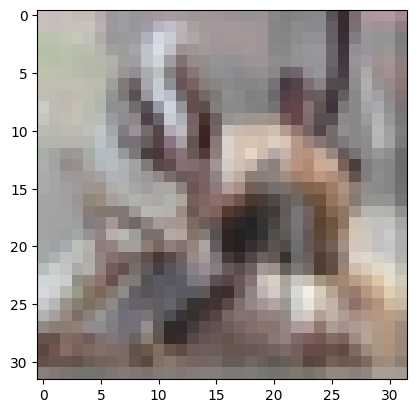

In [ ]:
x, y = next(datagen)

print("first: {}, second = {}".format(classes[np.argmax(y[0][0])],classes[np.argmax(y[1][0])+5]))
#print(np.min(x[0]),np.max(x[0]))
plt.imshow(x[0])

# Valutazione

Dfiniamo innanzi tutto il generatore di testing.

In [ ]:
testgen = datagenerator(cifar10_x_test_1,cifar10_x_test_2,cifar10_y_test_1,cifar10_y_test_2,10000)

eval_samples_x, eval_samples_y = next(testgen)
print(eval_samples_x.shape)

(10000, 32, 32, 3)


Testiamo con una nodello che produce predizioni random. Voi dovrete sostituire questo modello con il vostro modello predittivo.


# **Modello definito**
L'esercizio richiede un modello il cui obiettivo deve essere quello di classificare un immagine ottenuta come media di due immagini di Cifar10, il modello dovrà avere due output per descrivere entrambe le immagini di partenza.

Dovendo classificare un immagine è possibile utilizzare Reti per la classificazioni di immagini quali ResNet, Inception-v3 o VGC19.

Inizialmente avevo scelto di basare il mio modello su Resnet50, congelando i layer della rete per evitare di aggiornare i pesi durante il training in quanto è già allenata sul dataset di ImageNet ed è in grado di estrarre caratteristiche generali, poichè però l'immagine da riconoscere è ottenuta come media di due immagini  parte delle informazioni vengono perse, di conseguenza ho definito dei layer personalizzati sopra a Resnet, ottenendo però risultati non migliori di una rete formata solo da tali layer.

I layer personalizzati sono definiti come una tipica struttura di rete per la classificazione di immagini, ovvero una sequenza alternata di layer convoluzionali e downsampling, seguiti da flattening e livelli densi finali.

Ho quindi deciso di mantenere la rete semplice con i layer descritti, in quanto utilizzando Resnet ottenevo risultati peggiori.  

Utilizzo Dropout per evitare overfitting e migliorare la generalizzazione e una callback per ridurre dinamicamente il learning rate per stabilizzare l'allenamento.

(Dall'allenamento si può notare che l'accuracy dell'output2 è migliore di quella dell'output1, probabilmente il modello creato riesce a capire meglio le caratteristiche delle immagini appartenenti alla seconda categoria)

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization, Resizing, Input)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.layers import ZeroPadding2D


def resnet_based_model(input_shape=(32, 32, 3)):
    model_input = Input(shape=input_shape)
    """

    # Ridimensionamento delle immagini a 224x224 Resnet è stato progettato e pre-addestrato per lavorare con immagini di dimensioni 224x224
    x = Resizing(224, 224)(model_input)

    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))


    for layer in base_model.layers:
        layer.trainable = False


    # Aggiunta dei layer personalizzati sopra ResNet
    x = base_model(x)
    """

    x = Conv2D(64, (3, 3), activation='relu', padding='same')(model_input)
    x = BatchNormalization()(x)
    x = ZeroPadding2D(padding=(1, 1))(x)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = ZeroPadding2D(padding=(1, 1))(x)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    x = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = ZeroPadding2D(padding=(1, 1))(x)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    x = Flatten()(x)
    x = Dense(512, activation='relu', kernel_regularizer=l2(0.0015))(x)
    x = Dropout(0.6)(x)

    # Primo output
    x1 = Dense(128, activation='relu', kernel_regularizer=l2(0.0015))(x)
    x1 = BatchNormalization()(x1)
    x1 = Dropout(0.6)(x1)  # Increased Dropout
    output1 = Dense(5, activation='softmax', name='output1')(x1)

    # Secondo output
    x2 = Dense(128, activation='relu', kernel_regularizer=l2(0.0015))(x)
    x2 = BatchNormalization()(x2)
    x2 = Dropout(0.6)(x2)  # Increased Dropout
    output2 = Dense(5, activation='softmax', name='output2')(x2)


    model = Model(inputs=model_input, outputs=[output1, output2])
    return model


model = resnet_based_model()
optimizer = Adam(learning_rate=1e-4)
model.compile(
    optimizer=optimizer,
    loss=['categorical_crossentropy', 'categorical_crossentropy'],
    metrics=[['accuracy'], ['accuracy']]
)

model.summary()

# Callback per ridurre dinamicamente il learning rate
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.4,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# Impostazioni per il training
batch_size = 32
steps_per_epoch = cifar10_x_train_1.shape[0] // batch_size

# Training del modello
history = model.fit(
    datagenerator(cifar10_x_train_1, cifar10_x_train_2, cifar10_y_train_1, cifar10_y_train_2, batch_size),
    steps_per_epoch=steps_per_epoch,
    epochs=50,
    validation_data=testgen,
    validation_steps=100,
    callbacks=[reduce_lr]
)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5             │ (None, 32, 32, 3)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 32, 32, 64)     │          1,792 │ input_layer_5[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_5     │ (None, 32, 32, 64)     │            256 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d_3          │ (None, 34, 34, 64)     │              0 │ batch_normalization_5… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_3           │ (None, 17, 17, 64)     │              0 │ zero_padding2d_3[0][0] │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 17, 17, 128)    │         73,856 │ max_pooling2d_3[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_6     │ (None, 17, 17, 128)    │            512 │ conv2d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d_4          │ (None, 19, 19, 128)    │              0 │ batch_normalization_6… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_4           │ (None, 9, 9, 128)      │              0 │ zero_padding2d_4[0][0] │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 9, 9, 256)      │        295,168 │ max_pooling2d_4[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_7     │ (None, 9, 9, 256)      │          1,024 │ conv2d_5[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d_5          │ (None, 11, 11, 256)    │              0 │ batch_normalization_7… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_5           │ (None, 5, 5, 256)      │              0 │ zero_padding2d_5[0][0] │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten_2 (Flatten)       │ (None, 6400)           │              0 │ max_pooling2d_5[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_5 (Dense)      

 Total params: 3,783,562 (14.43 MB)

 Trainable params: 3,782,154 (14.43 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/50
781/781 ━━━━━━━━━━━━━━━━━━━━ 44s 42ms/step - loss: 6.9486 - output1_accuracy: 0.2689 - output1_loss: 2.5198 - output2_accuracy: 0.2767 - output2_loss: 2.4373 - val_loss: 4.6862 - val_output1_accuracy: 0.3960 - val_output1_loss: 1.4352 - val_output2_accuracy: 0.4496 - val_output2_loss: 1.3592 - learning_rate: 1.0000e-04
Epoch 2/50
781/781 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - loss: 5.8822 - output1_accuracy: 0.3217 - output1_loss: 2.0564 - output2_accuracy: 0.3423 - output2_loss: 1.9682 - val_loss: 4.4357 - val_output1_accuracy: 0.4404 - val_output1_loss: 1.3638 - val_output2_accuracy: 0.4780 - val_output2_loss: 1.3193 - learning_rate: 1.0000e-04
Epoch 3/50
781/781 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - loss: 5.2533 - output1_accuracy: 0.3571 - output1_loss: 1.8079 - output2_accuracy: 0.3781 - output2_loss: 1.7297 - val_loss: 4.2292 - val_output1_accuracy: 0.4358 - val_output1_loss: 1.3229 - val_output2_accuracy: 0.4635 - val_output2_loss: 1.3018 - learning_rate: 1.0000e-04
Epoc

In [ ]:
import tensorflow as tf
import numpy as np

def eval_model(model):
    eval_samples_x, eval_samples_y = next(testgen)
    predictions1, predictions2 = model(eval_samples_x)

    correct_guesses_1 = tf.argmax(predictions1, axis=1) == tf.argmax(eval_samples_y[0], axis=1)
    correct_guesses_2 = tf.argmax(predictions2, axis=1) == tf.argmax(eval_samples_y[1], axis=1)

    accuracy_1 = tf.reduce_mean(tf.cast(correct_guesses_1, tf.float32))
    accuracy_2 = tf.reduce_mean(tf.cast(correct_guesses_2, tf.float32))

    # Restituisci la media delle due accuratezze
    return (accuracy_1 + accuracy_2) / 2

In [ ]:

eval_model(model)

<tf.Tensor: shape=(), dtype=float32, numpy=0.71>

let us repeat the evaluation ten times, and comput the standard deviation

In [ ]:
repeat_eval = 10
eval_results = []
for i in range(repeat_eval):
  eval_results.append(eval_model(model))
print("mean accuracy = ", np.mean(eval_results))
print("standard deviation = ", np.std(eval_results))

mean accuracy =  0.71364
standard deviation =  0.0036588816
